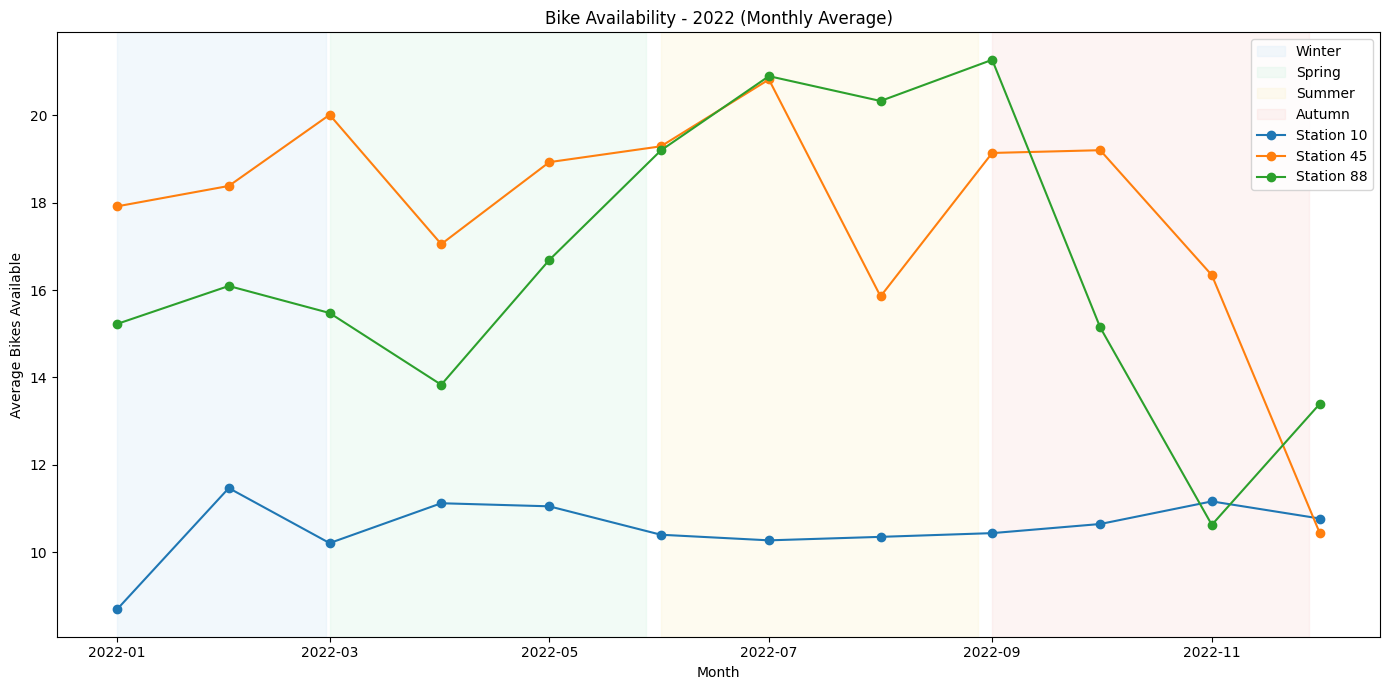

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

path = "dublin_bikes_all.csv"
dataset = pd.read_csv(path)

dataset["last_reported"] = pd.to_datetime(dataset["last_reported"])

year = 2022
dataset = dataset[dataset["last_reported"].dt.year == year]

stations = [10, 45, 88]
dataset = dataset[dataset["station_id"].isin(stations)].copy()

# Mensuel average (avoid noises)
dataset["month"] = dataset["last_reported"].dt.to_period("M")
monthly = dataset.groupby(["station_id", "month"])["num_bikes_available"].mean().reset_index()
monthly["month"] = monthly["month"].dt.to_timestamp()


plt.figure(figsize=(14,7))

# Define seasons with their corresponding months
seasons = {
    "Winter": (1, 2, "#D6EAF8"),
    "Spring": (3, 5, "#D5F5E3"),
    "Summer": (6, 8, "#FCF3CF"),
    "Autumn": (9, 11, "#FADBD8")
}


# Highlight seasons with background colors
for season, (start, end, color) in seasons.items():
    start_date = pd.Timestamp(year=year, month=start, day=1)
    end_date = pd.Timestamp(year=year, month=end, day=28)
    plt.axvspan(start_date, end_date, color=color, alpha=0.3, label=season)

# Plot
for station in stations:
    data = monthly[monthly["station_id"] == station]
    plt.plot(data["month"], data["num_bikes_available"], marker="o", label=f"Station {station}")


plt.title(f"Bike Availability - {year} (Monthly Average)")
plt.xlabel("Month")
plt.ylabel("Average Bikes Available")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Add a season column based on the month
dataset["season"] = dataset["last_reported"].dt.month.map(
    lambda m: "Winter" if m in [12,1,2] else
              "Spring" if m in [3,4,5] else
              "Summer" if m in [6,7,8] else
              "Autumn"
)

# Compute average bikes available by season
season_means = dataset.groupby("season")["num_bikes_available"].mean()

print("Number of bikes available by season:")
print(season_means)

Number of bikes available by season:
season
Autumn    15.452965
Spring    15.215827
Summer    16.287769
Winter    14.508685
Name: num_bikes_available, dtype: float64


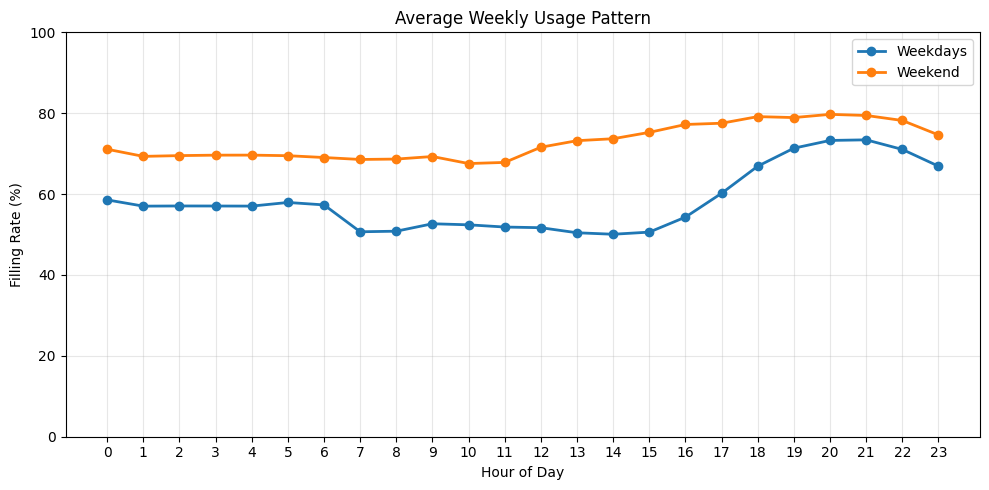

In [14]:
dataset["hour"] = dataset["last_reported"].dt.hour #if 8:30 -> 8, if 15:45 -> 15
dataset["weekday"] = dataset["last_reported"].dt.weekday  # 0=Monday 1=Tuesday ... 6=Sunday

# Random stations
stations = [10, 45, 65, 72, 90, 110, 115]

data = dataset[dataset["station_id"].isin(stations)].copy()


data["filling_rate"] = (
    data["num_bikes_available"] / data["capacity"] * 100
)

# Weekdays
week_data = data[data["weekday"] < 5]

# Weekend
weekend_data = data[data["weekday"] >= 5]

week_avg = week_data.groupby("hour")["filling_rate"].mean()
weekend_avg = weekend_data.groupby("hour")["filling_rate"].mean()

plt.figure(figsize=(10,5))

plt.plot(week_avg.index,
         week_avg.values,
         marker="o",
         linewidth=2,
         label="Weekdays")

plt.plot(weekend_avg.index,
         weekend_avg.values,
         marker="o",
         linewidth=2,
         label="Weekend")

plt.title("Average Weekly Usage Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Filling Rate (%)")
plt.ylim(0,100)
plt.xticks(range(0,24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()